<a href="https://colab.research.google.com/github/silvatria/pembelajaran-mesin-254107023001/blob/main/JS07_TL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- 1. INFORMASI DATASET ---
   Sl_No  Customer Key  Avg_Credit_Limit  Total_Credit_Cards  \
0      1         87073            100000                   2   
1      2         38414             50000                   3   
2      3         17341             50000                   7   
3      4         40496             30000                   5   
4      5         47437            100000                   6   

   Total_visits_bank  Total_visits_online  Total_calls_made  
0                  1                    1                 0  
1                  0                   10                 9  
2                  1                    3                 4  
3                  1                    1                 4  
4                  0                   12                 3  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No    

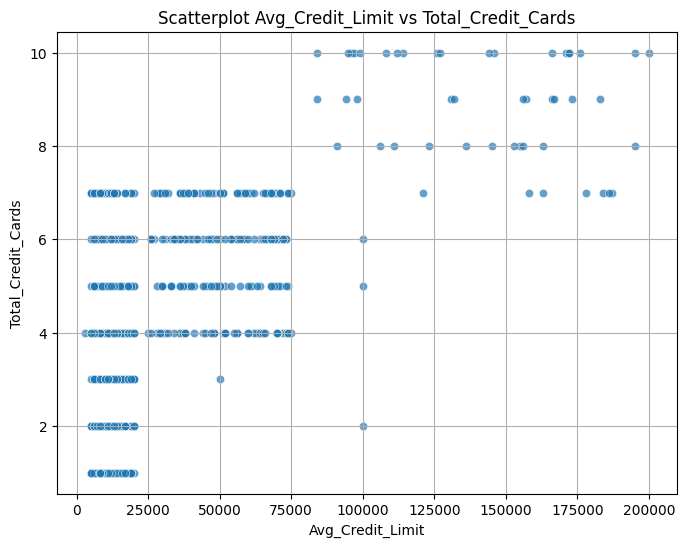

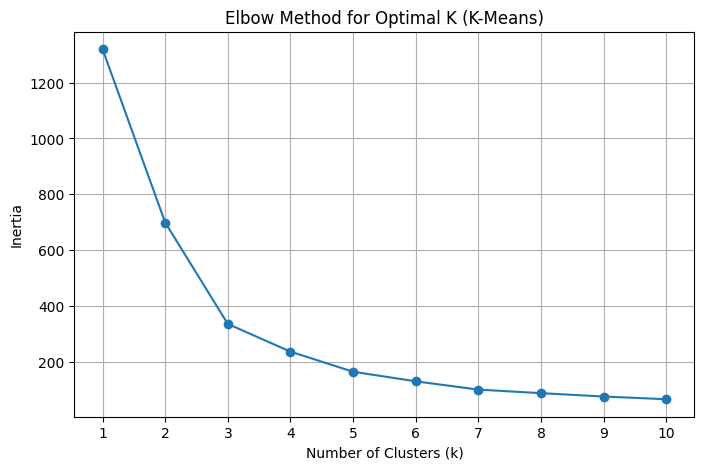

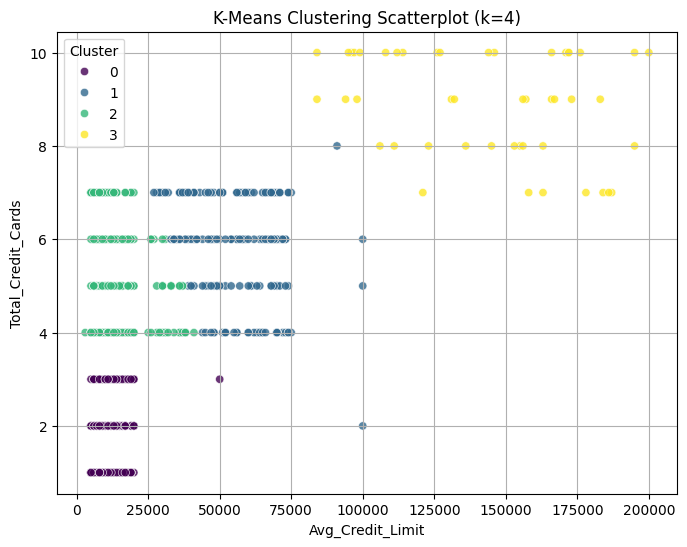


[Evaluasi K-Means k=4]
Silhouette Score : 0.4569
Davies-Bouldin Index (DBI): 0.8012

[Hasil DBSCAN]
Jumlah Klaster Terbentuk : 3
Jumlah Titik Noise (Anomali): 18
Silhouette Score (DBSCAN) : 0.5212
Davies-Bouldin Index (DBI): 2.1613


In [5]:
# Tugas Lab
# Klasterisasi Data Nasabah Kartu Kredit

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Load dataset
df = pd.read_csv('CC_Customer_Dataset.csv')

print("--- 1. INFORMASI DATASET ---")
print(df.head())
print(df.info())

# ==========================================
# 1. Scatterplot Avg_Credit_Limit vs Total_Credit_Cards
# ==========================================
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Avg_Credit_Limit', y='Total_Credit_Cards', alpha=0.7)
plt.title('Scatterplot Avg_Credit_Limit vs Total_Credit_Cards')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.grid(True)
plt.savefig('task1_scatter.png', bbox_inches='tight')
plt.show()

# ==========================================
# 2 & 3. K-Means & Elbow Method (Linechart)
# ==========================================
X_kmeans = df[['Avg_Credit_Limit', 'Total_Credit_Cards']]
scaler = StandardScaler()
X_kmeans_scaled = scaler.fit_transform(X_kmeans)

inertias = []
K_range = range(1, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_kmeans_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertias, marker='o', linestyle='-')
plt.title('Elbow Method for Optimal K (K-Means)')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.xticks(K_range)
plt.grid(True)
plt.savefig('task2_elbow.png', bbox_inches='tight')
plt.show()

# ==========================================
# 4. Scatterplot Hasil Klasterisasi K-Means (k=4)
# ==========================================
optimal_k = 4
kmeans_opt = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['Cluster_KMeans'] = kmeans_opt.fit_predict(X_kmeans_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x='Avg_Credit_Limit',
    y='Total_Credit_Cards',
    hue='Cluster_KMeans',
    palette='viridis',
    alpha=0.8
)
plt.title(f'K-Means Clustering Scatterplot (k={optimal_k})')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.legend(title='Cluster')
plt.grid(True)
plt.savefig('task3_kmeans_scatter.png', bbox_inches='tight')
plt.show()

# Evaluasi Metrik K-Means
km_silhouette = silhouette_score(X_kmeans_scaled, df['Cluster_KMeans'])
km_dbi = davies_bouldin_score(X_kmeans_scaled, df['Cluster_KMeans'])
print(f"\n[Evaluasi K-Means k={optimal_k}]")
print(f"Silhouette Score : {km_silhouette:.4f}")
print(f"Davies-Bouldin Index (DBI): {km_dbi:.4f}")

# ==========================================
# 5, 6, 7 & 8. DBSCAN Menggunakan Seluruh Variabel
# ==========================================
# Menggunakan seluruh variabel numerik yang relevan
X_dbscan = df[['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']]
X_dbscan_scaled = scaler.fit_transform(X_dbscan)

# Menjalankan DBSCAN (menggunakan eps=1.0, min_samples=5 sebagai baseline optimal)
dbscan = DBSCAN(eps=1.0, min_samples=5)
df['Cluster_DBSCAN'] = dbscan.fit_predict(X_dbscan_scaled)

labels = df['Cluster_DBSCAN']
n_clusters_db = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_db = list(labels).count(-1)

print(f"\n[Hasil DBSCAN]")
print(f"Jumlah Klaster Terbentuk : {n_clusters_db}")
print(f"Jumlah Titik Noise (Anomali): {n_noise_db}")

# Hitung Silhouette Score & DBI untuk DBSCAN (hanya jika klaster > 1 dan bukan noise murni)
if n_clusters_db > 1:
    db_silhouette = silhouette_score(X_dbscan_scaled, labels)
    db_dbi = davies_bouldin_score(X_dbscan_scaled, labels)
    print(f"Silhouette Score (DBSCAN) : {db_silhouette:.4f}")
    print(f"Davies-Bouldin Index (DBI): {db_dbi:.4f}")
else:
    print("DBSCAN menghasilkan klaster < 2, metrik evaluasi tidak dapat dihitung.")